# RF-ADC interleaving calibration on ZCU208

Hardware check and commissioning procedure for `ol.adc_cal` (`mimo_mts/drivers/adc_calibration.py`),
following PG269 *RF-ADC Calibration Mechanism*.

| Block | Corrects | After RF-ADC startup |
|---|---|---|
| OCB1 | sub-ADC offset | tracks in the background, cannot be frozen |
| OCB2 | offset, sampling-switch skew | set by foreground calibration, then frozen |
| GCB | sub-ADC gain | tracks; needs input above -40 dBFS; can be frozen |
| TSCB | sub-ADC time skew | tracks; needs input above -40 dBFS; can be frozen |

Writing coefficients enables the driver's per-block **override**: written values stay in use until
`release_override()`.

The notebook targets `MIMO_ZCU208` (real input, 4 GSPS, no decimation), where capture index == ADC channel.
Steps marked **[check]** answer the open hardware questions from the merge request; please record their outputs.

### Setup
* A CW signal into the ADC under test, from a signal generator or a DAC loopback cable (see step 3).
* Aim for about -10 dBFS at the ADC, well above the -40 dBFS GCB/TSCB threshold.

In [1]:
%cd /home/xilinx/jupyter_notebooks/pynq_llrf/

/home/xilinx/jupyter_notebooks/pynq_llrf


In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mimo_mts.overlay import MimoMtsOverlay

%load_ext autoreload
%autoreload 2

In [3]:
# CONFIG = "MIMO_ZCU208"
CONFIG = "ALS_LLRF_ZCU208"  # enable CW mode
ADC_CH = 0  # ADC channel under test
# Scratch file for this test. The IOCs default to /etc/mimo_mts/adc_cal.json; do not overwrite it here.
CAL_FILE = Path("/tmp/adc_cal_test.json")
N_AVG = 4  # captures averaged per spectrum

## 1. Load overlay

In [4]:
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
fs_hz = ol.adc_sampling_rate
print(cal)
print(f"Fs = {fs_hz / 1e9} GHz, ADC mixer: {ol.adc_mixer_nco_freq_mhz} MHz, Nyquist zone {ol.adc_mixer_nco_nyquist}")

LMK04828: Changing Reg 0x15f from 0x3e to 0x3b. Fix the .tcs!


Powering up and initializing analog frontend ...
<AdcCalibration: ADC channels [0, 1, 2, 3, 4, 5, 6, 7]>
Fs = 4.0 GHz, ADC mixer: 3000 MHz, Nyquist zone 2


## 2. [check] State after RF-ADC startup

Expected per PG269: background calibration tracking, i.e. **not** frozen.

In [5]:
blk = cal.block(ADC_CH)
print("raw CalFreeze:", blk.CalFreeze)
print("frozen:       ", cal.is_frozen())
print("cal. mode:    ", cal.calibration_mode())

raw CalFreeze: {'CalFrozen': 0, 'DisableFreezePin': 0, 'FreezeCalibration': 0}
frozen:        {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
cal. mode:     {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2}


**[check]** PYNQ coefficient calls with a CFFI struct (`GetCalCoefficients`). This should print four blocks of
8 coefficients for each ADC, without raising.

In [6]:
print(cal.report())

ADC0 (tile 0, block 0): tracking
  OCB1: [4293525453, 4290445262, 65544, 131078, 0, 0, 0, 0]
  OCB2: [5374002, 6225972, 4259918, 6160459, 0, 0, 0, 0]
  GCB : [65536, 65537, 65536, 1, 0, 0, 0, 0]
  TSCB: [33489407, 17367043, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]
ADC1 (tile 0, block 1): tracking
  OCB1: [4291100604, 4292673527, 4294770709, 4294574091, 0, 0, 0, 0]
  OCB2: [6553674, 7209031, 6946900, 6029392, 0, 0, 0, 0]
  GCB : [268369920, 268308478, 268304385, 0, 0, 0, 0, 0]
  TSCB: [33489407, 33489407, 983551, 33489407, 33489407, 33489407, 197119, 33489407]
ADC2 (tile 1, block 0): tracking
  OCB1: [4290838484, 4290510821, 4294377451, 524291, 0, 0, 0, 0]
  OCB2: [589826, 3014659, 4294180880, 1638419, 0, 0, 0, 0]
  GCB : [0, 268369921, 1, 1, 0, 0, 0, 0]
  TSCB: [33489407, 33488899, 33489407, 33489407, 33489407, 33489255, 33489407, 33489407]
ADC3 (tile 1, block 1): tracking
  OCB1: [4292673477, 4290314173, 4293722127, 4294836211, 0, 0, 0, 0]
  OCB2: [7077959, 7667783,

## 3. Trigger and input signal

Internal trigger, as in `mimo_mts.ipynb`; each trigger refills the ADC capture buffers.

In [7]:
rm = ol.rf_control.register_map
rm.trig_sel = 0  # internal trigger
rm.trig_period = 125e6  # 2 Hz at 250 MHz
rm.trig_delay = 0
rm.trig_divide = 1
rm.dac_enable = 1
rm.pulse_length = 0xFFF
TRIG_WAIT_S = 0.6  # > one trigger period

**Option A: signal generator** into ADC `ADC_CH`: CW, about -10 dBFS, at the frequency you calibrate for.
Skip the next cell.

**Option B: DAC loopback** (cable from a DAC to ADC `ADC_CH`): play a DC baseband through the DAC NCO, using a continous tone.

# Disable dac buffer, use llrf amplitude setpoint for CW signal

In [8]:
ol.dac_player[:] = np.zeros(ol.dac_player.size, dtype=np.int16)

In [9]:
ol.rf_control.register_map.amp_loop_setpoint = 32767 / ol.rf_control.tx_gain
ol.rf_control.register_map.phs_loop_setpoint = 0

In [10]:
ol

< MimoMtsOverlay >:
{ 'bitfile_name': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/overlays/zcu208/als_llrf_mts.bit'),
  'board': Board(name='ZCU208',
                 active_adc_tiles=15,
                 active_dac_tiles=15,
                 max_adc_sampling_rate=5000000000.0,
                 max_dac_sampling_rate=7000000000.0,
                 converters_per_tile=2,
                 adc_ref_tile=225,
                 dac_ref_tile=230),
  'clk104_tcs': { 'lmk_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMK04828_500M_CLKin0.tcs'),
                  'lmxadc_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_4G.tcs'),
                  'lmxdac_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_4G.tcs'),
                  'verify': True},
  'ioc': {'decimation': 2},
  'rfdc': { 'adc_decimation_factor': 8,
            'dac_interpolation_factor': 8,
            'mi

## 4. Spectrum helper

Averages `N_AVG` captures. Interleaving mismatch shows up as spurs at k·Fs/M and k·Fs/M ± f_in (M sub-ADCs).
The table lists the strongest components so the same numbers can be compared at each step.

In [11]:
def capture(ch=ADC_CH):
    time.sleep(TRIG_WAIT_S)
    i, q = ol.capture_adc_iq_buf()
    return i[ch].astype(np.float64) + 1j * q[ch].astype(np.float64)


def spectrum_dbfs(ch=ADC_CH, n_avg=N_AVG):
    psd = 0
    for _ in range(n_avg):
        x = capture(ch)
        win = np.blackman(len(x))
        psd = psd + np.abs(np.fft.fftshift(np.fft.fft(x * win)) / win.sum()) ** 2
    dbfs = 10 * np.log10(psd / n_avg / 32768.0**2 + 1e-30)
    f_mhz = np.fft.fftshift(np.fft.fftfreq(len(x), 1 / fs_hz)) / 1e6 + ol.adc_mixer_nco_freq_mhz
    return f_mhz, dbfs


def top_components(f_mhz, dbfs, n=8, guard=5):
    """n strongest peaks, ignoring +-guard bins around each one already picked."""
    d = dbfs.copy()
    rows = []
    for _ in range(n):
        k = int(np.argmax(d))
        rows.append((f_mhz[k], dbfs[k]))
        d[max(0, k - guard) : k + guard + 1] = -np.inf
    return rows


def measure(label, ch=ADC_CH):
    f, d = spectrum_dbfs(ch)
    comps = top_components(f, d)
    carrier = comps[0][1]
    spur = max(p for _, p in comps[1:])
    print(f"--- {label}: carrier {carrier:.1f} dBFS, worst listed spur {spur:.1f} dBFS ({carrier - spur:.1f} dBc)")
    for fm, p in comps:
        print(f"    {fm:10.3f} MHz  {p:7.1f} dBFS")
    return f, d


results = {}

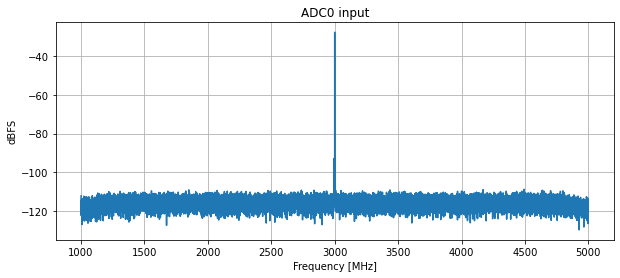

In [12]:
f, d = spectrum_dbfs()
plt.figure(figsize=(10, 4))
plt.plot(f, d)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} input")
plt.grid(True)

## 5. Train: background calibration tracking on the CW signal

Make sure the ADCs are tracking, then wait for convergence. PG269 gives time constants of 2^20 to 2^22 samples
(about 1 ms at 4 GSPS); a few seconds is plenty.

In [13]:
print(cal.unfreeze())
time.sleep(5)
results["tracking"] = measure("tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- tracking: carrier -27.6 dBFS, worst listed spur -92.5 dBFS (64.9 dBc)
      3000.000 MHz    -27.6 dBFS
      3003.418 MHz    -92.5 dBFS
      2996.582 MHz    -92.7 dBFS
      2995.850 MHz   -104.1 dBFS
      3004.150 MHz   -105.0 dBFS
      3001.099 MHz   -107.7 dBFS
      2998.047 MHz   -107.9 dBFS
      4000.000 MHz   -108.2 dBFS


## 6. Freeze and save

**[check]** `freeze()` should return `True` for every channel, and `CalFreeze` should now show
`DisableFreezePin=1, FreezeCalibration=1, CalFrozen=1`.

In [14]:
print(cal.freeze())
print("raw CalFreeze:", cal.block(ADC_CH).CalFreeze)
cal.save(CAL_FILE)
results["frozen"] = measure("frozen")

{0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
raw CalFreeze: {'CalFrozen': 1, 'DisableFreezePin': 1, 'FreezeCalibration': 1}
--- frozen: carrier -27.6 dBFS, worst listed spur -87.9 dBFS (60.3 dBc)
      3000.000 MHz    -27.6 dBFS
      3003.418 MHz    -87.9 dBFS
      2996.582 MHz    -87.9 dBFS
      3002.686 MHz   -103.4 dBFS
      2997.314 MHz   -103.4 dBFS
      3004.150 MHz   -107.5 dBFS
      2995.239 MHz   -108.1 dBFS
      4147.949 MHz   -108.3 dBFS


In [15]:
import json

print(json.dumps(cal.load(CAL_FILE)[f"ADC{ADC_CH}"], indent=1)[:1500])

{
 "adc_ch": 0,
 "tile": 0,
 "block": 0,
 "board": "ZCU208",
 "overlay": "ALS_LLRF_ZCU208",
 "adc_sampling_rate_hz": 4000000000.0,
 "nyquist_zone": 2,
 "saved_at": "2026-11-07T01:03:38+00:00",
 "coeffs": {
  "OCB1": [
   4293394376,
   4290183093,
   196612,
   131081,
   0,
   0,
   0,
   0
  ],
  "OCB2": [
   5374002,
   6225972,
   4259918,
   6160459,
   0,
   0,
   0,
   0
  ],
  "GCB": [
   11407359,
   11141341,
   11403268,
   2162817,
   0,
   0,
   0,
   0
  ],
  "TSCB": [
   33489407,
   33488899,
   33489407,
   33489407,
   33489407,
   33489407,
   33489407,
   33489407
  ]
 }
}


## 7. Demonstrate: overwrite GCB/TSCB with zeros

This only shows the effect of the coefficients. It writes zeros with the override enabled, so the ADC is
deliberately miscalibrated until step 8.

In [16]:
cal.write({ADC_CH: {"GCB": [0] * 8, "TSCB": [0] * 8}})
print(cal.report(ADC_CH))
results["zeroed"] = measure("GCB/TSCB zeroed")

ADC0 (tile 0, block 0): FROZEN
  OCB1: [4293394378, 4290379703, 327684, 9, 0, 0, 0, 0]
  OCB2: [5374002, 6225972, 4259918, 6160459, 0, 0, 0, 0]
  GCB : [0, 0, 0, 0, 0, 0, 0, 0]
  TSCB: [33489407, 33488899, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]
--- GCB/TSCB zeroed: carrier -27.6 dBFS, worst listed spur -90.9 dBFS (63.3 dBc)
      3000.000 MHz    -27.6 dBFS
      2996.582 MHz    -90.9 dBFS
      3003.418 MHz    -91.0 dBFS
      3002.686 MHz   -105.4 dBFS
      2997.681 MHz   -106.1 dBFS
      3000.977 MHz   -107.3 dBFS
      2995.850 MHz   -107.3 dBFS
      4000.000 MHz   -108.1 dBFS


## 8. Restore and verify

`restore()` writes GCB/TSCB from the file (override on), freezes, and verifies by read-back. An empty list per
channel means verified. OCB1/OCB2 are left to the hardware by default.

In [18]:
mismatches = cal.restore(CAL_FILE)
print(mismatches)
results["restored"] = measure("restored")

{0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: []}
--- restored: carrier -27.6 dBFS, worst listed spur -91.8 dBFS (64.3 dBc)
      3000.000 MHz    -27.6 dBFS
      2996.582 MHz    -91.8 dBFS
      3003.418 MHz    -92.1 dBFS
      3002.686 MHz   -105.7 dBFS
      2995.605 MHz   -106.7 dBFS
      2997.314 MHz   -106.7 dBFS
      3004.395 MHz   -107.5 dBFS
      2998.901 MHz   -107.5 dBFS


In [19]:
print("verify, all blocks:", cal.verify(CAL_FILE))

verify, all blocks: {0: ['OCB1: hw=[4293328841, 4290379704, 327685, 65545, 0, 0, 0, 0] file=[4293394376, 4290183093, 196612, 131081, 0, 0, 0, 0]'], 1: ['OCB1: hw=[4291559352, 4292280313, 65556, 4294508554, 0, 0, 0, 0] file=[4291428279, 4292345849, 4294901779, 4294508555, 0, 0, 0, 0]'], 2: ['OCB1: hw=[4290969549, 4290248660, 4294377450, 393219, 0, 0, 0, 0] file=[4291035085, 4290183124, 4294442987, 393221, 0, 0, 0, 0]'], 3: ['OCB1: hw=[4292739016, 4289986485, 4293656582, 4294836211, 0, 0, 0, 0] file=[4292476871, 4289986486, 4293656583, 4294967283, 0, 0, 0, 0]'], 4: ['OCB1: hw=[4290576352, 4294115270, 4294901785, 524275, 0, 0, 0, 0] file=[4290510817, 4294180804, 4294901788, 589810, 0, 0, 0, 0]'], 5: ['OCB1: hw=[4292607940, 4291887038, 196610, 4294443015, 0, 0, 0, 0] file=[4292411333, 4291952575, 327683, 4294508550, 0, 0, 0, 0]'], 6: ['OCB1: hw=[4290314177, 4288675777, 4293984259, 4293722107, 0, 0, 0, 0] file=[4290379713, 4288610242, 4294115330, 4293853182, 0, 0, 0, 0]'], 7: ['OCB1: hw=[42

## 9. Release override and resume tracking

`release_override()` returns all blocks to engine-computed values, then `unfreeze()` resumes GCB/TSCB tracking.

In [20]:
cal.release_override()
print(cal.unfreeze())
time.sleep(5)
results["released"] = measure("released + tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- released + tracking: carrier -27.6 dBFS, worst listed spur -91.5 dBFS (63.9 dBc)
      3000.000 MHz    -27.6 dBFS
      2996.582 MHz    -91.5 dBFS
      3003.418 MHz    -91.8 dBFS
      3001.953 MHz   -104.3 dBFS
      2997.314 MHz   -104.5 dBFS
      3002.686 MHz   -105.7 dBFS
      2998.047 MHz   -106.1 dBFS
      3001.099 MHz   -107.3 dBFS


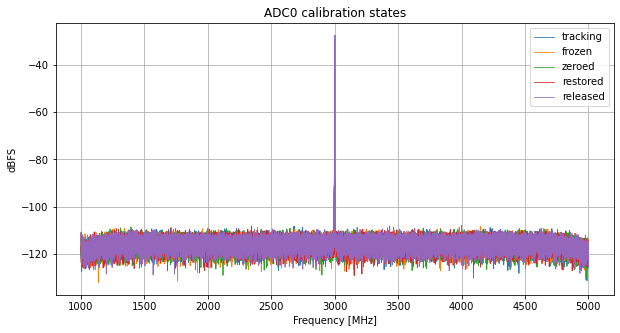

In [21]:
plt.figure(figsize=(10, 5))
for label, (f, d) in results.items():
    plt.plot(f, d, label=label, lw=0.8)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} calibration states")
plt.legend()
plt.grid(True)

## 10. [check] Restore after a fresh overlay load

The production flow (`AlsLlrfLBL208`): load the overlay, restore, freeze. The spectrum should match the
"restored" result from step 8.

In [22]:
ol.free()
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
print("after reload, frozen:", cal.is_frozen())
rm = ol.rf_control.register_map
rm.trig_sel, rm.trig_period, rm.trig_delay, rm.trig_divide = 0, 125e6, 0, 1
rm.dac_enable, rm.pulse_length = 1, 0xFFF
# Re-run the Option B cell here if using DAC loopback.

LMK04828: Changing Reg 0x15f from 0x3e to 0x3b. Fix the .tcs!


Powering up and initializing analog frontend ...
after reload, frozen: {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}


In [23]:
print(cal.restore(CAL_FILE))
results["reload + restore"] = measure("reload + restore")

ADC calibration restore did not verify: {0: ['TSCB: hw=[33161727, 19726339, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407] file=[33489407, 33488899, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]'], 1: ['TSCB: hw=[33489407, 33489407, 33489194, 33489407, 33489407, 33489407, 33488899, 33489407] file=[33489407, 33489407, 4981247, 33489407, 33489407, 33489407, 197119, 33489407]'], 2: ['TSCB: hw=[33489407, 33489407, 33488899, 33489407, 33489407, 33489407, 33489160, 33489407] file=[33489407, 33488899, 33489407, 33489407, 33489407, 33489295, 33489407, 33489407]'], 3: ['TSCB: hw=[33489407, 197119, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407] file=[33489407, 33489407, 33489407, 33489407, 33489407, 33489407, 33488899, 33489407]'], 4: ['TSCB: hw=[33488899, 33489407, 33489407, 33489407, 18416059, 33489407, 33489407, 33489407] file=[33489407, 33489407, 33489407, 33489407, 33489407, 197119, 33489407, 33489407]'], 5: ['TSCB: hw=[33489407, 6029823, 33489407, 33

{0: ['TSCB: hw=[33161727, 19726339, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407] file=[33489407, 33488899, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]'], 1: ['TSCB: hw=[33489407, 33489407, 33489194, 33489407, 33489407, 33489407, 33488899, 33489407] file=[33489407, 33489407, 4981247, 33489407, 33489407, 33489407, 197119, 33489407]'], 2: ['TSCB: hw=[33489407, 33489407, 33488899, 33489407, 33489407, 33489407, 33489160, 33489407] file=[33489407, 33488899, 33489407, 33489407, 33489407, 33489295, 33489407, 33489407]'], 3: ['TSCB: hw=[33489407, 197119, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407] file=[33489407, 33489407, 33489407, 33489407, 33489407, 33489407, 33488899, 33489407]'], 4: ['TSCB: hw=[33488899, 33489407, 33489407, 33489407, 18416059, 33489407, 33489407, 33489407] file=[33489407, 33489407, 33489407, 33489407, 33489407, 197119, 33489407, 33489407]'], 5: ['TSCB: hw=[33489407, 6029823, 33489407, 33489407, 33489407, 197119, 33489407, 3348

## 11. [check] Optional: re-run foreground calibration

`restart_adc_tiles()` resets the ADC tiles (foreground calibration runs again), re-synchronizes MTS (DAC tiles are
reset too) and restores the default mixers. **Mute the ADC input first**: PG269 requires no signal energy at k·Fs/M
during foreground calibration.

Record: does it complete, does `check_mts_latency()` pass, and are freeze state and overrides cleared?

In [24]:
# Mute the input (signal generator RF off, or the next line for DAC loopback) before running.
zeros = np.zeros(ol.dac_player.size // 2, dtype=np.int16)
ol.write_dac_iq_buf(zeros, zeros)

ol.rf_control.register_map.amp_loop_setpoint = 0
ol.rf_control.register_map.phs_loop_setpoint = 0

ol.restart_adc_tiles()
ol.check_mts_latency()
print(ol.report_mts_latency())
print("frozen after restart:", cal.is_frozen())
print(cal.report(ADC_CH))

< RFDC MTS Latency: >
  DAC Tile 0 Latency: 256, Offset: 2
  DAC Tile 1 Latency: 256, Offset: 2
  DAC Tile 2 Latency: 256, Offset: 2
  DAC Tile 3 Latency: 256, Offset: 2
  ADC Tile 0 Latency:  96, Offset: 1
  ADC Tile 1 Latency:  96, Offset: 1
  ADC Tile 2 Latency:  96, Offset: 1
  ADC Tile 3 Latency:  96, Offset: 1

frozen after restart: {0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
ADC0 (tile 0, block 0): FROZEN
  OCB1: [4293132222, 4290052042, 4294836228, 1507330, 0, 0, 0, 0]
  OCB2: [5898301, 6750282, 4587610, 7143514, 0, 0, 0, 0]
  GCB : [268369920, 268369921, 4095, 268242943, 0, 0, 0, 0]
  TSCB: [33161727, 19726339, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]


## Results to report
1. Step 2: raw `CalFreeze` and frozen state after load.
2. Step 2: `cal.report()` ran without error.
3. Step 6: `freeze()` result and raw `CalFreeze`.
4. Steps 5-10: carrier and worst-spur levels for each state.
5. Step 10: restore after reload matches step 8.
6. Step 11: foreground re-run result.